# Неделя 12. Bagging, Random Forest и OOB: зачем усреднять деревья

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 108 минут практики (2 × 54 минуты). На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** увидеть bootstrap-выборку, собрать небольшой ансамбль вручную, сравнить bagging и случайный лес, понять границы OOB и оценить устойчивость.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_12_random_forest'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Данные и граница между обучением и проверкой

`sample_id` нужен для аудита разделения, **не для обучения**. `target` — ответ;
его нельзя включать в признаки. Проверки схемы выполняем для всего CSV,
а содержательный EDA — только для обучающей части. Test откроем после фиксации
модели и правила принятия решений. Фиксированный seed делает опыт повторяемым,
но не превращает одно разделение в доказательство универсальности результата.


In [2]:
df = pd.read_csv(DATA / 'wine.csv').set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
X = df.drop(columns="target")
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
assert "target" not in X_train and "sample_id" not in X_train
print({"train": X_train.shape, "sealed_test": X_test.shape})
display(X_train.head(3))


{'train': (133, 13), 'sealed_test': (45, 13)}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
sample_id,,,,,,,,,,,,,
8,14.83,1.64,2.17,14.0,97,2.8,2.98,0.29,1.98,5.20,1.08,2.85,1045
104,12.51,1.73,1.98,20.5,85,2.2,1.92,0.32,1.48,2.94,1.04,3.57,672
36,13.28,1.64,2.84,15.5,110,2.6,2.68,0.34,1.36,4.60,1.09,2.78,880


## 1. EDA и baseline

Продолжаем Wine, но эксперимент выполняем с нуля и с тем же фиксированным
train/test split. Размер мал: главным ограничением становится вариативность
оценки, а не время обучения. Деревья не требуют стандартизации для этой задачи.


,count,mean,std,min,25%,50%,75%,max
alcohol,133.0,12.97,0.80,11.03,12.37,12.99,13.56,14.83
malic_acid,133.0,2.33,1.09,0.74,1.61,1.81,3.12,5.80
ash,133.0,2.37,0.27,1.36,2.20,2.36,2.56,3.22
alcalinity_of_ash,133.0,19.70,3.37,10.60,17.20,20.00,21.50,30.00
magnesium,133.0,100.00,14.98,70.00,88.00,98.00,108.00,162.00
total_phenols,133.0,2.28,0.63,0.98,1.70,2.40,2.80,3.88
flavanoids,133.0,1.99,0.96,0.34,1.22,2.14,2.78,3.74
nonflavanoid_phenols,133.0,0.36,0.12,0.13,0.27,0.34,0.43,0.63
proanthocyanins,133.0,1.60,0.59,0.42,1.25,1.57,1.95,3.58
color_intensity,133.0,5.01,2.37,1.28,3.05,4.68,6.25,13.00


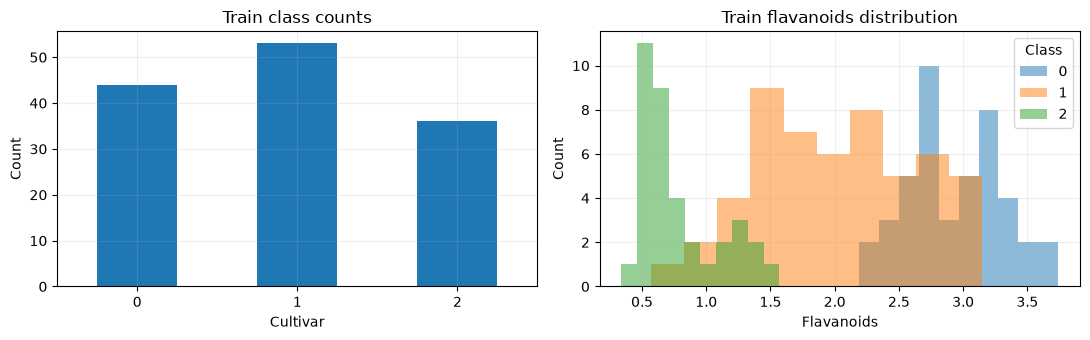

In [3]:
display(X_train.describe().T.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
y_train.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Train class counts", xlabel="Cultivar", ylabel="Count")
for label in sorted(y_train.unique()):
    axes[1].hist(X_train.loc[y_train == label, "flavanoids"], bins=10, alpha=0.5, label=str(label))
axes[1].set(title="Train flavanoids distribution", xlabel="Flavanoids", ylabel="Count")
axes[1].legend(title="Class"); plt.tight_layout(); plt.show()


## 2. Bootstrap и out-of-bag

Bootstrap выбирает $n$ строк из $n$ **с возвращением**. Вероятность, что строка
ни разу не попадёт в выборку: $(1-1/n)^n\approx e^{-1}\approx0.368$.
Такие строки — OOB для конкретного дерева. OOB у каждого дерева свой.
Это не означает, что 36.8% исходных данных образуют один общий test.


Строк в bootstrap: 133 ; уникальных: 77
Доля OOB: 0.42105263157894735 ; теоретически: 0.36649208667222244


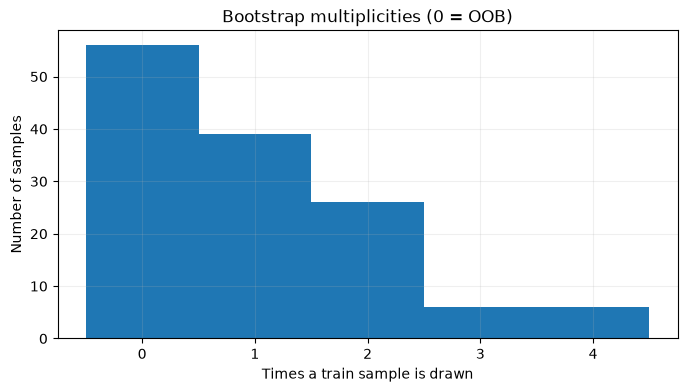

In [4]:
n_train = len(X_train)
sampled_positions = rng.integers(0, n_train, size=n_train)
counts = np.bincount(sampled_positions, minlength=n_train)
oob_positions = np.flatnonzero(counts == 0)
assert counts.sum() == n_train and len(oob_positions) > 0
print("Строк в bootstrap:", len(sampled_positions), "; уникальных:", np.count_nonzero(counts))
print("Доля OOB:", len(oob_positions)/n_train, "; теоретически:", (1-1/n_train)**n_train)
plt.hist(counts, bins=np.arange(counts.max()+2)-0.5)
plt.xlabel("Times a train sample is drawn"); plt.ylabel("Number of samples")
plt.title("Bootstrap multiplicities (0 = OOB)"); plt.show()


## 3. Bagging своими руками на внутреннем validation

У каждого дерева собственная bootstrap-выборка. Для классификации усредняем
вероятности и выбираем максимальную. Случайный лес добавляет случайный набор
признаков при **каждом split**; наш ручной bagging использует все признаки.


In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, accuracy_score
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25,
    stratify=y_train, random_state=SEED + 1)
manual_trees, probabilities = [], []
bootstrap_rng = np.random.default_rng(SEED)
for tree_id in range(25):
    positions = bootstrap_rng.integers(0, len(X_fit), size=len(X_fit))
    tree = DecisionTreeClassifier(random_state=SEED + tree_id)
    tree.fit(X_fit.iloc[positions], y_fit.iloc[positions])
    # Выравниваем классы: bootstrap теоретически может пропустить редкий класс.
    aligned = np.zeros((len(X_val), 3))
    aligned[:, tree.classes_.astype(int)] = tree.predict_proba(X_val)
    manual_trees.append(tree); probabilities.append(aligned)
ensemble_probability = np.mean(probabilities, axis=0)
assert np.allclose(ensemble_probability.sum(axis=1), 1)
print("Manual bagging validation macro F1:", f1_score(y_val, ensemble_probability.argmax(axis=1), average="macro"))


Manual bagging validation macro F1: 0.942089879430033


## 4. Почему усреднение может помочь

Если ошибки одинаково распределены с дисперсией $\sigma^2$ и попарной корреляцией
$\rho$, то дисперсия среднего $B$ моделей равна
$$\operatorname{Var}(\bar f)=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2.$$

Число деревьев уменьшает второе слагаемое, но не первое. Случайные признаки
стремятся снизить корреляцию. Формула — иллюстрация при упрощающих предположениях,
не оценка реальной дисперсии нашего леса.


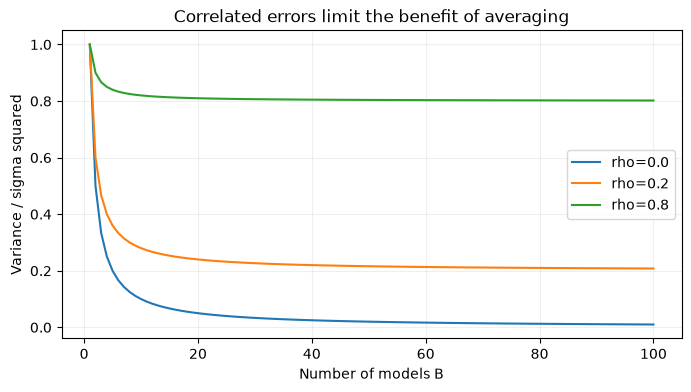

In [6]:
trees_count = np.arange(1, 101)
for rho in [0.0, 0.2, 0.8]:
    plt.plot(trees_count, rho + (1-rho)/trees_count, label=f"rho={rho}")
plt.xlabel("Number of models B"); plt.ylabel("Variance / sigma squared")
plt.title("Correlated errors limit the benefit of averaging"); plt.legend(); plt.show()


## 5. Сравнение single tree, bagging и Random Forest на общих folds

Выбираем заранее macro F1 и четыре stratified folds. `n_jobs=1` и фиксированные
seeds делают вычисления удобными для обычного ноутбука. `max_features='sqrt'`
в лесу ограничивает кандидатов на каждом разделении.


In [7]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
candidates = {
    "majority baseline": DummyClassifier(strategy="most_frequent"),
    "single tree": DecisionTreeClassifier(random_state=SEED),
    "bagging": BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=80,
                                 bootstrap=True, random_state=SEED, n_jobs=1),
    "random forest": RandomForestClassifier(n_estimators=100, max_features="sqrt",
                                            random_state=SEED, n_jobs=1)}
rows = []
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, scoring="f1_macro", cv=cv, n_jobs=1)
    rows.append({"model": name, "CV_macro_F1": scores.mean(), "fold_SD": scores.std()})
display(pd.DataFrame(rows).round(3))


,model,CV_macro_F1,fold_SD
0,majority baseline,0.190,0.003
1,single tree,0.920,0.067
2,bagging,0.956,0.049
3,random forest,0.978,0.024


## 6. OOB в библиотечном лесу

Для каждого train-объекта предсказание собирается только из деревьев, где объект
не встречался при обучении. `oob_score_` по умолчанию — **accuracy**, не macro F1.
Рассчитаем macro F1 вручную по `oob_decision_function_`, явно проверив покрытие.


In [8]:
oob_forest = RandomForestClassifier(n_estimators=180, oob_score=True, bootstrap=True,
    max_features="sqrt", random_state=SEED, n_jobs=1).fit(X_train, y_train)
oob_probability = oob_forest.oob_decision_function_
covered = np.isfinite(oob_probability).all(axis=1) & (oob_probability.sum(axis=1) > 0)
assert covered.all(), "Увеличьте количество деревьев: есть строки без OOB-прогнозов"
oob_pred = oob_forest.classes_[oob_probability.argmax(axis=1)]
print("OOB accuracy:", oob_forest.oob_score_)
print("OOB macro F1:", f1_score(y_train, oob_pred, average="macro"))
assert np.isclose(accuracy_score(y_train, oob_pred), oob_forest.oob_score_)


OOB accuracy: 0.9774436090225563
OOB macro F1: 0.9775369347748534


## 7. Подбор параметров и честный смысл OOB

Выбор `min_samples_leaf` и `max_features` выполняем на CV train. Если многократно
выбирать параметры по OOB, он становится validation-критерием и также может
переоценивать победителя. Внешний test всё равно остаётся закрытым.


In [9]:
from sklearn.model_selection import GridSearchCV
search = GridSearchCV(RandomForestClassifier(n_estimators=120, random_state=SEED, n_jobs=1),
    {"max_features": ["sqrt", 0.7], "min_samples_leaf": [1, 3, 7]},
    scoring="f1_macro", cv=cv, n_jobs=1)
search.fit(X_train, y_train)
display(pd.DataFrame(search.cv_results_)[["param_max_features", "param_min_samples_leaf", "mean_test_score", "std_test_score"]])
print("Зафиксированные параметры:", search.best_params_)


,param_max_features,param_min_samples_leaf,mean_test_score,std_test_score
0,sqrt,1,0.977861,0.024081
1,sqrt,3,0.977861,0.024081
2,sqrt,7,0.985581,0.024975
3,0.7,1,0.956083,0.048820
4,0.7,3,0.956083,0.048820
5,0.7,7,0.948984,0.059885


Зафиксированные параметры: {'max_features': 'sqrt', 'min_samples_leaf': 7}


## 8. Устойчивость к seed на внутреннем validation

Устойчивость — отдельный вопрос. Меняем seed ансамбля, сохраняя данные и
параметры. **Не выбираем лучший seed**: это спрятанный подбор модели.
Здесь измеряется вариативность обучения на данном split, а не полная неопределённость.


In [10]:
stability = []
for seed in [11, 22, 33, 44, 55]:
    fitted = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1,
                                    **search.best_params_).fit(X_fit, y_fit)
    stability.append({"seed": seed, "validation_macro_F1": f1_score(y_val, fitted.predict(X_val), average="macro")})
stability_table = pd.DataFrame(stability)
display(stability_table)
print("Разброс (sample SD):", stability_table.validation_macro_F1.std())


,seed,validation_macro_F1
0,11,0.973162
1,22,0.942322
2,33,0.973162
3,44,0.973162
4,55,0.973162


Разброс (sample SD): 0.01379171232186106


## 9. Важность признаков: измеряем на validation

Impurity importance — внутренний счётчик дерева и может предпочитать признаки
с большим числом возможных разделений. Permutation importance измеряет падение
метрики при перемешивании столбца; связанные признаки могут замещать друг друга.
Используем модель на fit и validation, чтобы не настраиваться по test.


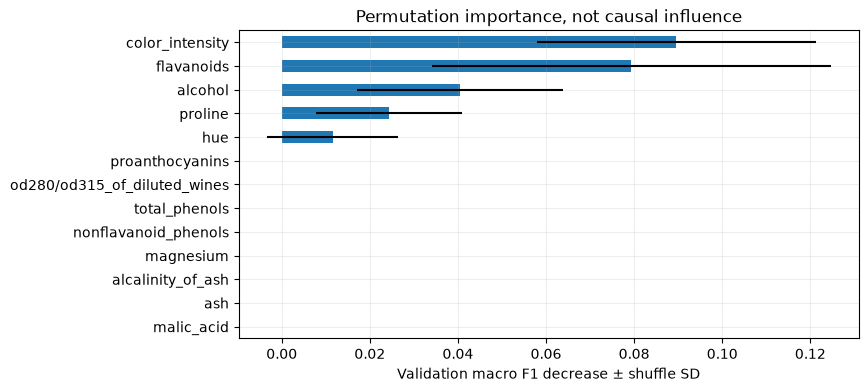

In [11]:
from sklearn.inspection import permutation_importance
explain_model = RandomForestClassifier(n_estimators=120, random_state=SEED, n_jobs=1,
    **search.best_params_).fit(X_fit, y_fit)
permutation = permutation_importance(explain_model, X_val, y_val, n_repeats=8,
    random_state=SEED, scoring="f1_macro", n_jobs=1)
importance = pd.Series(permutation.importances_mean, index=X_train.columns).sort_values()
importance.plot.barh(xerr=pd.Series(permutation.importances_std, index=X_train.columns).loc[importance.index])
plt.xlabel("Validation macro F1 decrease ± shuffle SD")
plt.title("Permutation importance, not causal influence"); plt.show()


## 10. Итоговый test

Модель выбрана по CV и переобучена на полном train. OOB, validation и final test
отвечают на разные вопросы; не выбираем из них наиболее красивое число.


              precision    recall  f1-score   support

           0       0.94      1.00      0.97        15
           1       1.00      0.94      0.97        18
           2       1.00      1.00      1.00        12

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



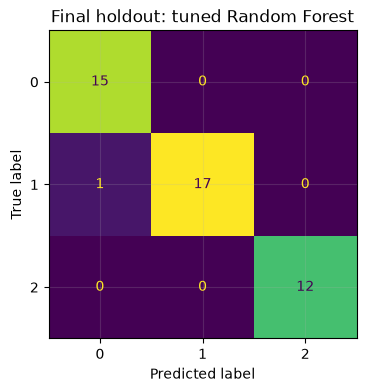

In [12]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
final_prediction = search.predict(X_test)
print(classification_report(y_test, final_prediction, zero_division=0))
assert final_prediction.shape == y_test.shape
ConfusionMatrixDisplay.from_predictions(y_test, final_prediction, colorbar=False)
plt.title("Final holdout: tuned Random Forest"); plt.show()


## Что объяснить в отчёте

Как формируются bootstrap и OOB? Чем Random Forest отличается от bagging?
Почему число деревьев не устраняет корреляцию ошибок? Почему OOB accuracy нельзя
напрямую сравнивать с CV macro F1? Какие ограничения есть у permutation importance?

Первоисточники: [Breiman, Random Forests (2001)](https://www.stat.berkeley.edu/~breiman/randomforest2001.pdf),
[scikit-learn ensembles](https://scikit-learn.org/stable/modules/ensemble.html),
[OOB example](https://scikit-learn.org/stable/auto_examples/ensemble/plot_ensemble_oob.html),
[permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
